In [1]:
import os
import json
import random
import shutil
import numpy as np
import pandas as pd
import torch

from datasets import Dataset
from sentence_transformers import (
    SentenceTransformer,
    SentenceTransformerTrainer,
    SentenceTransformerTrainingArguments
)
from sentence_transformers.sentence_transformer.losses import (
    MultipleNegativesRankingLoss
)

from IPython.display import display

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("GPU is not enabled. Enable a Kaggle GPU accelerator first.")

print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory:",
    round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
    "GB"
)

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [2]:
DATA_DIR = (
    "/kaggle/input/datasets/"
    "patzeradi/patent-intelligence-finetuning-pairs-v2"
)

train = pd.read_csv(os.path.join(DATA_DIR, "train_pairs.csv"))
validation = pd.read_csv(os.path.join(DATA_DIR, "validation_pairs.csv"))
test = pd.read_csv(os.path.join(DATA_DIR, "test_pairs.csv"))

print("Training shape:", train.shape)
print("Validation shape:", validation.shape)
print("Test shape:", test.shape)

print("\nColumns:", train.columns.tolist())

display(train.head(3))

Training shape: (39291, 6)
Validation shape: (2770, 6)
Test shape: (2751, 6)

Columns: ['anchor_id', 'positive_id', 'anchor_text', 'positive_text', 'shared_cpc_count', 'cpc_jaccard']


,anchor_id,positive_id,anchor_text,positive_text,shared_cpc_count,cpc_jaccard
0,14996551,14995691,Title: METHOD FOR PROCESS OPERATORS TO PERSONA...,Title: DIGITAL MOTOR CONTROLLER STABILITY ANAL...,1,0.250000
1,15011614,15007924,"Title: Terminal mechanism, Permanent Magnet Ad...",Title: METHOD FOR MAKING A POWER CONNECTION\nA...,1,0.333333
2,14993526,14903487,"Title: METHOD, DEVICE AND SYSTEM FOR PROJECTIO...",Title: Multiband Wireless Communication Method...,2,0.285714


In [3]:
required_columns = [
    "anchor_id",
    "positive_id",
    "anchor_text",
    "positive_text",
    "shared_cpc_count",
    "cpc_jaccard"
]

for name, df in [
    ("train", train),
    ("validation", validation),
    ("test", test)
]:
    missing = set(required_columns) - set(df.columns)

    if missing:
        raise ValueError(f"{name} is missing columns: {missing}")

    print(f"\n{name.upper()}")
    print("Rows:", len(df))
    print("Missing values:")
    print(df[required_columns].isnull().sum())

    assert df["anchor_id"].notna().all()
    assert df["positive_id"].notna().all()
    assert df["anchor_text"].notna().all()
    assert df["positive_text"].notna().all()

    assert (df["anchor_id"] != df["positive_id"]).all()

print("\nData validation completed.")


TRAIN
Rows: 39291
Missing values:
anchor_id           0
positive_id         0
anchor_text         0
positive_text       0
shared_cpc_count    0
cpc_jaccard         0
dtype: int64

VALIDATION
Rows: 2770
Missing values:
anchor_id           0
positive_id         0
anchor_text         0
positive_text       0
shared_cpc_count    0
cpc_jaccard         0
dtype: int64

TEST
Rows: 2751
Missing values:
anchor_id           0
positive_id         0
anchor_text         0
positive_text       0
shared_cpc_count    0
cpc_jaccard         0
dtype: int64

Data validation completed.


In [4]:
MODEL_NAME = "BAAI/bge-base-en-v1.5"

MAX_SEQ_LENGTH = 256
DEVICE = "cuda"

print("Loading pretrained model:", MODEL_NAME)

baseline_model = SentenceTransformer(
    MODEL_NAME,
    device=DEVICE
)

baseline_model.max_seq_length = MAX_SEQ_LENGTH

sample_text = train.iloc[0]["anchor_text"]

sample_embedding = baseline_model.encode(
    sample_text,
    convert_to_tensor=True,
    normalize_embeddings=True
)

print("Model loaded.")
print("Device:", baseline_model.device)
print("Embedding shape:", sample_embedding.shape)

Loading pretrained model: BAAI/bge-base-en-v1.5


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Model loaded.
Device: cuda:0
Embedding shape: torch.Size([768])


In [5]:
def build_retrieval_data(pair_df):

    patents = {}

    for row in pair_df.itertuples(index=False):
        patents.setdefault(row.anchor_id, row.anchor_text)
        patents.setdefault(row.positive_id, row.positive_text)

    queries = {}
    qrels = {}

    for row in pair_df.itertuples(index=False):
        queries[row.anchor_id] = row.anchor_text

        qrels.setdefault(row.anchor_id, set()).add(
            row.positive_id
        )

    corpus_ids = list(patents.keys())
    corpus_texts = [patents[pid] for pid in corpus_ids]

    query_ids = list(queries.keys())
    query_texts = [queries[qid] for qid in query_ids]

    return {
        "corpus_ids": corpus_ids,
        "corpus_texts": corpus_texts,
        "query_ids": query_ids,
        "query_texts": query_texts,
        "qrels": qrels
    }

In [6]:
def evaluate_retrieval(
    model,
    pair_df,
    dataset_name="validation",
    k_values=(1, 5, 10, 20),
    batch_size=64
):

    eval_data = build_retrieval_data(pair_df)

    corpus_ids = eval_data["corpus_ids"]
    corpus_texts = eval_data["corpus_texts"]

    query_ids = eval_data["query_ids"]
    query_texts = eval_data["query_texts"]

    qrels = eval_data["qrels"]

    print(f"\nEvaluating on {dataset_name}")
    print("Corpus size:", len(corpus_ids))
    print("Query count:", len(query_ids))

    corpus_embeddings = model.encode(
        corpus_texts,
        batch_size=batch_size,
        convert_to_tensor=True,
        normalize_embeddings=True,
        show_progress_bar=True
    )

    query_embeddings = model.encode(
        query_texts,
        batch_size=batch_size,
        convert_to_tensor=True,
        normalize_embeddings=True,
        show_progress_bar=True
    )

    scores = query_embeddings @ corpus_embeddings.T

    corpus_id_to_index = {
        pid: idx for idx, pid in enumerate(corpus_ids)
    }

    # A query must not retrieve itself.
    for query_index, query_id in enumerate(query_ids):
        if query_id in corpus_id_to_index:
            scores[
                query_index,
                corpus_id_to_index[query_id]
            ] = -torch.inf

    max_k = min(max(k_values), len(corpus_ids))

    top_scores, top_indices = torch.topk(
        scores,
        k=max_k,
        dim=1
    )

    top_indices = top_indices.cpu().numpy()

    results = []

    for k in k_values:

        recall_values = []
        reciprocal_ranks = []
        ndcg_values = []

        for i, query_id in enumerate(query_ids):

            relevant = qrels.get(query_id, set())

            if not relevant:
                continue

            retrieved_ids = [
                corpus_ids[index]
                for index in top_indices[i][:k]
            ]

            hits = [
                1 if pid in relevant else 0
                for pid in retrieved_ids
            ]

            recall = sum(hits) / len(relevant)

            reciprocal_rank = 0.0

            for rank, hit in enumerate(hits, start=1):
                if hit:
                    reciprocal_rank = 1.0 / rank
                    break

            dcg = sum(
                hit / np.log2(rank + 1)
                for rank, hit in enumerate(hits, start=1)
            )

            ideal_hits = min(len(relevant), k)

            idcg = sum(
                1.0 / np.log2(rank + 1)
                for rank in range(1, ideal_hits + 1)
            )

            ndcg = dcg / idcg if idcg > 0 else 0.0

            recall_values.append(recall)
            reciprocal_ranks.append(reciprocal_rank)
            ndcg_values.append(ndcg)

        results.append({
            "Dataset": dataset_name,
            "K": k,
            "Recall@K": np.mean(recall_values),
            "MRR@K": np.mean(reciprocal_ranks),
            "nDCG@K": np.mean(ndcg_values)
        })

    return pd.DataFrame(results)

In [7]:
baseline_validation = evaluate_retrieval(
    model=baseline_model,
    pair_df=validation,
    dataset_name="validation_baseline"
)

display(baseline_validation)


Evaluating on validation_baseline
Corpus size: 1803
Query count: 1281


Batches:   0%|          | 0/29 [00:00<?, ?it/s]

Batches:   0%|          | 0/21 [00:00<?, ?it/s]

,Dataset,K,Recall@K,MRR@K,nDCG@K
0,validation_baseline,1,0.107665,0.188134,0.188134
1,validation_baseline,5,0.260315,0.261267,0.218661
2,validation_baseline,10,0.356895,0.277565,0.256399
3,validation_baseline,20,0.464793,0.285351,0.289968


In [8]:
OUTPUT_ROOT = "/kaggle/working/patent-bge-experiments"

os.makedirs(OUTPUT_ROOT, exist_ok=True)

baseline_validation.to_csv(
    os.path.join(OUTPUT_ROOT, "baseline_validation_metrics.csv"),
    index=False
)

In [9]:
train_dataset = Dataset.from_dict({
    "anchor": train["anchor_text"].tolist(),
    "positive": train["positive_text"].tolist()
})

print("Training examples:", len(train_dataset))
print("Columns:", train_dataset.column_names)

assert len(train_dataset) == len(train)

Training examples: 39291
Columns: ['anchor', 'positive']


In [10]:
MODEL_OUTPUT = os.path.join(
    OUTPUT_ROOT,
    "bge_patent_mnrl"
)

training_model = SentenceTransformer(
    MODEL_NAME,
    device=DEVICE
)

training_model.max_seq_length = MAX_SEQ_LENGTH

train_loss = MultipleNegativesRankingLoss(training_model)

training_args = SentenceTransformerTrainingArguments(
    output_dir=MODEL_OUTPUT,

    num_train_epochs=1,

    per_device_train_batch_size=16,

    learning_rate=2e-5,

    warmup_steps=0.1,

    fp16=True,
    bf16=False,

    batch_sampler="no_duplicates",

    logging_steps=50,

    save_strategy="epoch",
    save_total_limit=2,

    report_to="none",

    seed=SEED,

    dataloader_num_workers=2
)

trainer = SentenceTransformerTrainer(
    model=training_model,
    args=training_args,
    train_dataset=train_dataset,
    loss=train_loss
)

print("Training configuration ready.")
print("Training pairs:", len(train_dataset))
print("Batch size:", 16)
print("Epochs:", 1)
print("Learning rate:", 2e-5)
print("Output:", MODEL_OUTPUT)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Currently using DataParallel (DP) for multi-gpu training, while DistributedDataParallel (DDP) is recommended for faster training. See https://sbert.net/docs/sentence_transformer/training/distributed.html for more information.


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Training configuration ready.
Training pairs: 39291
Batch size: 16
Epochs: 1
Learning rate: 2e-05
Output: /kaggle/working/patent-bge-experiments/bge_patent_mnrl


In [11]:
train_result = trainer.train()

print("\nFine-tuning completed.")

print("\nTraining metrics:")
print(train_result.metrics)

Step,Training Loss
50,1.511543
100,1.074404
150,0.952334
200,0.937559
250,0.911800
300,0.930049
350,0.917902
400,0.881339
450,0.828273
500,0.839859


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Fine-tuning completed.

Training metrics:
{'train_runtime': 1797.1052, 'train_samples_per_second': 21.863, 'train_steps_per_second': 0.683, 'total_flos': 0.0, 'train_loss': 0.8650458581284514, 'epoch': 1.0}


In [12]:
trainer.save_model(MODEL_OUTPUT)

print("Fine-tuned model saved to:")
print(MODEL_OUTPUT)

print("\nSaved files:")
print(os.listdir(MODEL_OUTPUT))


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fine-tuned model saved to:
/kaggle/working/patent-bge-experiments/bge_patent_mnrl

Saved files:
['sentence_bert_config.json', 'README.md', '2_Normalize', '1_Pooling', 'training_args.bin', 'modules.json', 'config_sentence_transformers.json', 'config.json', 'tokenizer_config.json', 'tokenizer.json', 'checkpoint-1228', 'model.safetensors']


In [13]:
fine_tuned_model = SentenceTransformer(
    MODEL_OUTPUT,
    device=DEVICE
)

fine_tuned_model.max_seq_length = MAX_SEQ_LENGTH

print("Fine-tuned model loaded.")
print("Device:", fine_tuned_model.device)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Fine-tuned model loaded.
Device: cuda:0


In [14]:
finetuned_validation = evaluate_retrieval(
    model=fine_tuned_model,
    pair_df=validation,
    dataset_name="validation_finetuned"
)

display(finetuned_validation)


Evaluating on validation_finetuned
Corpus size: 1803
Query count: 1281


Batches:   0%|          | 0/29 [00:00<?, ?it/s]

Batches:   0%|          | 0/21 [00:00<?, ?it/s]

,Dataset,K,Recall@K,MRR@K,nDCG@K
0,validation_finetuned,1,0.128749,0.220921,0.220921
1,validation_finetuned,5,0.329733,0.308652,0.269683
2,validation_finetuned,10,0.443325,0.324736,0.315407
3,validation_finetuned,20,0.577130,0.333813,0.357647


In [15]:
baseline_comparison = baseline_validation.copy()
finetuned_comparison = finetuned_validation.copy()

comparison = baseline_comparison.merge(
    finetuned_comparison,
    on="K",
    suffixes=("_baseline", "_finetuned")
)

comparison["Recall improvement"] = (
    comparison["Recall@K_finetuned"]
    - comparison["Recall@K_baseline"]
)

comparison["MRR improvement"] = (
    comparison["MRR@K_finetuned"]
    - comparison["MRR@K_baseline"]
)

comparison["nDCG improvement"] = (
    comparison["nDCG@K_finetuned"]
    - comparison["nDCG@K_baseline"]
)

display(comparison)

comparison.to_csv(
    os.path.join(OUTPUT_ROOT, "validation_comparison.csv"),
    index=False
)

,Dataset_baseline,K,Recall@K_baseline,MRR@K_baseline,nDCG@K_baseline,Dataset_finetuned,Recall@K_finetuned,MRR@K_finetuned,nDCG@K_finetuned,Recall improvement,MRR improvement,nDCG improvement
0,validation_baseline,1,0.107665,0.188134,0.188134,validation_finetuned,0.128749,0.220921,0.220921,0.021084,0.032787,0.032787
1,validation_baseline,5,0.260315,0.261267,0.218661,validation_finetuned,0.329733,0.308652,0.269683,0.069418,0.047385,0.051021
2,validation_baseline,10,0.356895,0.277565,0.256399,validation_finetuned,0.443325,0.324736,0.315407,0.086430,0.047171,0.059007
3,validation_baseline,20,0.464793,0.285351,0.289968,validation_finetuned,0.577130,0.333813,0.357647,0.112337,0.048462,0.067679


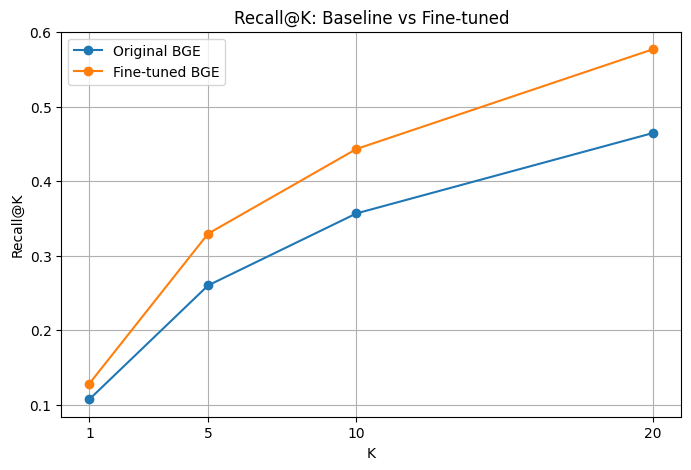

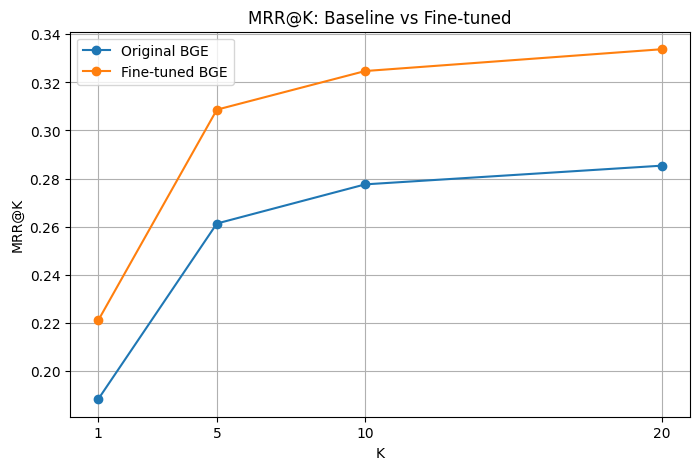

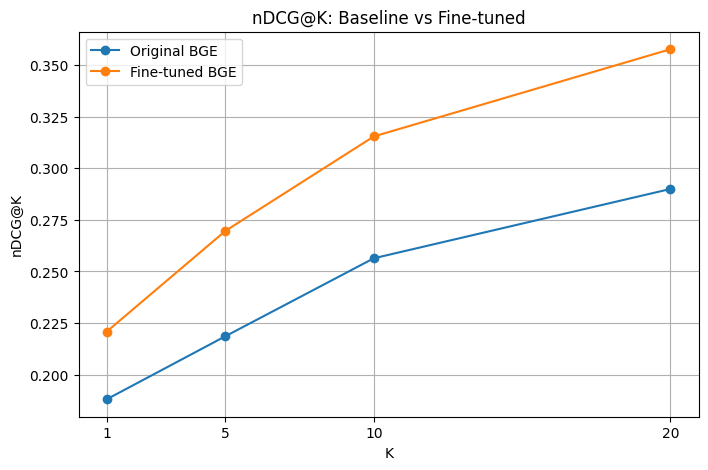

In [16]:
import matplotlib.pyplot as plt

metrics = ["Recall@K", "MRR@K", "nDCG@K"]

for metric in metrics:

    plt.figure(figsize=(8, 5))

    plt.plot(
        comparison["K"],
        comparison[f"{metric}_baseline"],
        marker="o",
        label="Original BGE"
    )

    plt.plot(
        comparison["K"],
        comparison[f"{metric}_finetuned"],
        marker="o",
        label="Fine-tuned BGE"
    )

    plt.xlabel("K")
    plt.ylabel(metric)
    plt.title(f"{metric}: Baseline vs Fine-tuned")
    plt.xticks(comparison["K"])
    plt.legend()
    plt.grid(True)
    plt.show()

In [17]:
baseline_test = evaluate_retrieval(
    model=baseline_model,
    pair_df=test,
    dataset_name="test_baseline"
)

finetuned_test = evaluate_retrieval(
    model=fine_tuned_model,
    pair_df=test,
    dataset_name="test_finetuned"
)

test_comparison = baseline_test.merge(
    finetuned_test,
    on="K",
    suffixes=("_baseline", "_finetuned")
)

test_comparison["Recall improvement"] = (
    test_comparison["Recall@K_finetuned"]
    - test_comparison["Recall@K_baseline"]
)

test_comparison["MRR improvement"] = (
    test_comparison["MRR@K_finetuned"]
    - test_comparison["MRR@K_baseline"]
)

test_comparison["nDCG improvement"] = (
    test_comparison["nDCG@K_finetuned"]
    - test_comparison["nDCG@K_baseline"]
)

display(test_comparison)

test_comparison.to_csv(
    os.path.join(OUTPUT_ROOT, "test_comparison.csv"),
    index=False
)


Evaluating on test_baseline
Corpus size: 1783
Query count: 1262


Batches:   0%|          | 0/28 [00:00<?, ?it/s]

Batches:   0%|          | 0/20 [00:00<?, ?it/s]


Evaluating on test_finetuned
Corpus size: 1783
Query count: 1262


Batches:   0%|          | 0/28 [00:00<?, ?it/s]

Batches:   0%|          | 0/20 [00:00<?, ?it/s]

,Dataset_baseline,K,Recall@K_baseline,MRR@K_baseline,nDCG@K_baseline,Dataset_finetuned,Recall@K_finetuned,MRR@K_finetuned,nDCG@K_finetuned,Recall improvement,MRR improvement,nDCG improvement
0,test_baseline,1,0.100906,0.170365,0.170365,test_finetuned,0.121919,0.214739,0.214739,0.021014,0.044374,0.044374
1,test_baseline,5,0.251023,0.252219,0.210115,test_finetuned,0.326790,0.314078,0.266383,0.075768,0.061859,0.056268
2,test_baseline,10,0.339630,0.267227,0.244981,test_finetuned,0.436178,0.329553,0.310211,0.096548,0.062326,0.065230
3,test_baseline,20,0.451169,0.275528,0.279879,test_finetuned,0.565573,0.338211,0.351165,0.114405,0.062683,0.071287


In [18]:
# Save training metrics
with open(
    os.path.join(OUTPUT_ROOT, "training_metrics.json"),
    "w"
) as f:
    json.dump(train_result.metrics, f, indent=4, default=str)

# Save experiment configuration
experiment_config = {
    "base_model": MODEL_NAME,
    "loss": "MultipleNegativesRankingLoss",
    "training_pairs": len(train_dataset),
    "epochs": 1,
    "batch_size": 16,
    "learning_rate": 2e-5,
    "max_sequence_length": MAX_SEQ_LENGTH,
    "seed": SEED
}

with open(
    os.path.join(OUTPUT_ROOT, "experiment_config.json"),
    "w"
) as f:
    json.dump(experiment_config, f, indent=4)

print("Experiment files:")
for root, dirs, files in os.walk(OUTPUT_ROOT):
    for file in files:
        print(os.path.join(root, file))

Experiment files:
/kaggle/working/patent-bge-experiments/training_metrics.json
/kaggle/working/patent-bge-experiments/baseline_validation_metrics.csv
/kaggle/working/patent-bge-experiments/test_comparison.csv
/kaggle/working/patent-bge-experiments/validation_comparison.csv
/kaggle/working/patent-bge-experiments/experiment_config.json
/kaggle/working/patent-bge-experiments/bge_patent_mnrl/sentence_bert_config.json
/kaggle/working/patent-bge-experiments/bge_patent_mnrl/README.md
/kaggle/working/patent-bge-experiments/bge_patent_mnrl/training_args.bin
/kaggle/working/patent-bge-experiments/bge_patent_mnrl/modules.json
/kaggle/working/patent-bge-experiments/bge_patent_mnrl/config_sentence_transformers.json
/kaggle/working/patent-bge-experiments/bge_patent_mnrl/config.json
/kaggle/working/patent-bge-experiments/bge_patent_mnrl/tokenizer_config.json
/kaggle/working/patent-bge-experiments/bge_patent_mnrl/tokenizer.json
/kaggle/working/patent-bge-experiments/bge_patent_mnrl/model.safetensors
/

In [19]:
archive_path = shutil.make_archive(
    "/kaggle/working/patent-bge-experiment-results",
    "zip",
    OUTPUT_ROOT
)

print("Archive created:")
print(archive_path)

Archive created:
/kaggle/working/patent-bge-experiment-results.zip


In [20]:
from sentence_transformers.sentence_transformer.losses import ContrastiveLoss
from sklearn.neighbors import NearestNeighbors

# Reconstruct unique patents from training pairs only.
patent_corpus = {}

for row in train.itertuples(index=False):
    patent_corpus.setdefault(row.anchor_id, row.anchor_text)
    patent_corpus.setdefault(row.positive_id, row.positive_text)

corpus_df = pd.DataFrame([
    {"patent_id": pid, "text": text}
    for pid, text in patent_corpus.items()
])

corpus_df = corpus_df.drop_duplicates(
    subset=["patent_id"]
).reset_index(drop=True)

# Remove empty or duplicate text records.
corpus_df["text"] = corpus_df["text"].astype(str).str.strip()
corpus_df = corpus_df[
    corpus_df["text"].ne("")
].drop_duplicates(subset=["text"]).reset_index(drop=True)

print("Unique training patents:", len(corpus_df))
display(corpus_df.head())

Unique training patents: 19403


,patent_id,text
0,14996551,Title: METHOD FOR PROCESS OPERATORS TO PERSONA...
1,14995691,Title: DIGITAL MOTOR CONTROLLER STABILITY ANAL...
2,15011614,"Title: Terminal mechanism, Permanent Magnet Ad..."
3,15007924,Title: METHOD FOR MAKING A POWER CONNECTION\nA...
4,14993526,"Title: METHOD, DEVICE AND SYSTEM FOR PROJECTIO..."


In [21]:
teacher_model = SentenceTransformer(
    MODEL_NAME,
    device=DEVICE
)

teacher_model.max_seq_length = MAX_SEQ_LENGTH

teacher_embeddings = teacher_model.encode(
    corpus_df["text"].tolist(),
    batch_size=32,
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=True
)

print("Embedding shape:", teacher_embeddings.shape)
print("Embedding dtype:", teacher_embeddings.dtype)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/607 [00:00<?, ?it/s]

Embedding shape: (19403, 768)
Embedding dtype: float32


In [24]:

from sklearn.neighbors import NearestNeighbors

TOP_NEIGHBORS = 20

nn = NearestNeighbors(
    n_neighbors=TOP_NEIGHBORS + 1,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

nn.fit(teacher_embeddings)

distances, indices = nn.kneighbors(teacher_embeddings)

print("Distances shape:", distances.shape)
print("Indices shape:", indices.shape)


Distances shape: (19403, 21)
Indices shape: (19403, 21)


In [25]:
# Inspect cosine similarities of nearest neighbours
nearest_similarities = 1.0 - distances[:, 1:]

print("Nearest-neighbour similarity statistics:")
print("Maximum:", nearest_similarities.max())
print("Minimum:", nearest_similarities.min())
print("Mean:", nearest_similarities.mean())
print("Median:", np.median(nearest_similarities))

print("\nPercentiles:")
for p in [50, 75, 90, 95, 99, 100]:
    print(f"{p}th percentile:",
          np.percentile(nearest_similarities, p))

print("\nPairs above different thresholds:")
for threshold in [0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75]:
    count = np.sum(nearest_similarities >= threshold)
    print(f">= {threshold}: {count}")

Nearest-neighbour similarity statistics:
Maximum: 1.0
Minimum: 0.59776413
Mean: 0.77023774
Median: 0.7660004

Percentiles:
50th percentile: 0.7660004
75th percentile: 0.79216355
90th percentile: 0.82360035
95th percentile: 0.84666586
99th percentile: 0.8971461
100th percentile: 1.0

Pairs above different thresholds:
>= 0.4: 388060
>= 0.45: 388060
>= 0.5: 388060
>= 0.55: 388060
>= 0.6: 388055
>= 0.65: 387514
>= 0.7: 377153
>= 0.75: 263130


In [26]:
rng = np.random.default_rng(SEED)

sampled_similarities = []

for _ in range(10000):
    i, j = rng.choice(len(teacher_embeddings), size=2, replace=False)

    similarity = np.dot(
        teacher_embeddings[i],
        teacher_embeddings[j]
    )

    sampled_similarities.append(similarity)

sampled_similarities = np.array(sampled_similarities)

print("Random-pair similarity distribution:")
for p in [1, 5, 10, 25, 50, 75, 90, 95, 99]:
    print(f"{p}th percentile: {np.percentile(sampled_similarities, p):.4f}")

Random-pair similarity distribution:
1th percentile: 0.4639
5th percentile: 0.4990
10th percentile: 0.5171
25th percentile: 0.5470
50th percentile: 0.5804
75th percentile: 0.6134
90th percentile: 0.6457
95th percentile: 0.6666
99th percentile: 0.7115


In [27]:

POSITIVE_THRESHOLD = 0.75
NEGATIVE_THRESHOLD = 0.55

TOP_NEIGHBORS = 20
RANDOM_CANDIDATES = 50

ids = corpus_df["patent_id"].tolist()
texts = corpus_df["text"].tolist()

# Exclude known CPC-positive relationships from negative mining.
cpc_positive_edges = set()

for row in train.itertuples(index=False):
    cpc_positive_edges.add((row.anchor_id, row.positive_id))
    cpc_positive_edges.add((row.positive_id, row.anchor_id))

# Find nearest semantic neighbours.
nn = NearestNeighbors(
    n_neighbors=min(TOP_NEIGHBORS + 1, len(corpus_df)),
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

nn.fit(teacher_embeddings)
distances, indices = nn.kneighbors(teacher_embeddings)

similarity_pairs = []
rng = np.random.default_rng(SEED)

for anchor_idx in range(len(corpus_df)):

    anchor_id = ids[anchor_idx]

    # Find the nearest positive above the threshold.
    positive_candidates = []

    for distance, candidate_idx in zip(
        distances[anchor_idx][1:],
        indices[anchor_idx][1:]
    ):
        similarity = 1.0 - float(distance)

        if similarity >= POSITIVE_THRESHOLD:
            positive_candidates.append((candidate_idx, similarity))

    if not positive_candidates:
        continue

    positive_idx, positive_similarity = positive_candidates[0]
    positive_id = ids[positive_idx]

    # Sample random candidates for negative mining.
    candidates = rng.choice(
        len(corpus_df),
        size=min(RANDOM_CANDIDATES, len(corpus_df)),
        replace=False
    )

    valid_candidates = []

    for candidate_idx in candidates:
        candidate_id = ids[candidate_idx]

        if candidate_idx == anchor_idx:
            continue

        if candidate_idx == positive_idx:
            continue

        if (anchor_id, candidate_id) in cpc_positive_edges:
            continue

        similarity = float(
            np.dot(
                teacher_embeddings[anchor_idx],
                teacher_embeddings[candidate_idx]
            )
        )

        if similarity <= NEGATIVE_THRESHOLD:
            valid_candidates.append((candidate_idx, similarity))

    if not valid_candidates:
        continue

    # Select the closest candidate that still qualifies as a negative.
    negative_idx, negative_similarity = max(
        valid_candidates,
        key=lambda x: x[1]
    )

    similarity_pairs.append({
        "anchor_id": anchor_id,
        "positive_id": positive_id,
        "anchor_text": texts[anchor_idx],
        "positive_text": texts[positive_idx],
        "positive_similarity": positive_similarity,
        "negative_id": ids[negative_idx],
        "negative_text": texts[negative_idx],
        "negative_similarity": negative_similarity
    })

similarity_pairs_df = pd.DataFrame(
    similarity_pairs,
    columns=[
        "anchor_id", "positive_id", "anchor_text",
        "positive_text", "positive_similarity",
        "negative_id", "negative_text", "negative_similarity"
    ]
)

print("Generated anchors:", len(similarity_pairs_df))

if similarity_pairs_df.empty:
    raise RuntimeError(
        "No pairs generated. Recheck thresholds and candidate mining."
    )

display(similarity_pairs_df.head())

print("\nPositive similarity:")
print(similarity_pairs_df["positive_similarity"].describe())

print("\nNegative similarity:")
print(similarity_pairs_df["negative_similarity"].describe())

similarity_pairs_df.to_csv(
    os.path.join(OUTPUT_ROOT, "similarity_mined_pairs.csv"),
    index=False
)


Generated anchors: 18309


,anchor_id,positive_id,anchor_text,positive_text,positive_similarity,negative_id,negative_text,negative_similarity
0,14996551,14996107,Title: METHOD FOR PROCESS OPERATORS TO PERSONA...,Title: METHOD AND DEVICE FOR FAULT DETECTION\n...,0.797125,14986889,Title: ROD ELEVATOR\nAbstract: A rod elevator ...,0.545747
1,14995691,14907501,Title: DIGITAL MOTOR CONTROLLER STABILITY ANAL...,Title: AUTOMATED METHOD FOR ANALYZING A BOARD ...,0.787972,14990245,Title: RECTIFICATION APPARATUS OF STEREO VISIO...,0.540051
2,15011614,14908196,"Title: Terminal mechanism, Permanent Magnet Ad...",Title: PERMANENT MAGNET-EMBEDDED ELECTRIC MOTO...,0.809467,15009796,Title: Methods and Systems for Navigation with...,0.548499
3,15007924,14995805,Title: METHOD FOR MAKING A POWER CONNECTION\nA...,Title: Air-Tight connection system for electro...,0.823852,15006237,Title: PORTABLE URINATION STATION\nAbstract: A...,0.545387
4,14993526,14993654,"Title: METHOD, DEVICE AND SYSTEM FOR PROJECTIO...","Title: PROJECTOR, PROJECTION DISPLAY SYSTEM, A...",0.803092,15007369,Title: ELECTROSTATIC CHARGE IMAGE DEVELOPING T...,0.549175



Positive similarity:
count    18309.000000
mean         0.828945
std          0.053173
min          0.750025
25%          0.791017
50%          0.817010
75%          0.852965
max          1.000000
Name: positive_similarity, dtype: float64

Negative similarity:
count    18309.000000
mean         0.546272
std          0.005391
min          0.469503
25%          0.545513
50%          0.547871
75%          0.549150
max          0.550000
Name: negative_similarity, dtype: float64


In [30]:
contrastive_rows = []

for row in similarity_pairs_df.itertuples(index=False):

    contrastive_rows.append({
        "sentence1": row.anchor_text,
        "sentence2": row.positive_text,
        "label": 1.0
    })

    contrastive_rows.append({
        "sentence1": row.anchor_text,
        "sentence2": row.negative_text,
        "label": 0.0
    })

similarity_training_df = pd.DataFrame(contrastive_rows)

print("Total contrastive examples:", len(similarity_training_df))
print(similarity_training_df["label"].value_counts())

similarity_dataset = Dataset.from_pandas(
    similarity_training_df,
    preserve_index=False
)

Total contrastive examples: 36618
label
1.0    18309
0.0    18309
Name: count, dtype: int64


In [31]:
similarity_model = SentenceTransformer(
    MODEL_NAME,
    device=DEVICE
)

similarity_model.max_seq_length = MAX_SEQ_LENGTH

similarity_loss = ContrastiveLoss(
    model=similarity_model
)

SIMILARITY_OUTPUT = os.path.join(
    OUTPUT_ROOT,
    "bge_similarity_contrastive"
)

similarity_args = SentenceTransformerTrainingArguments(
    output_dir=SIMILARITY_OUTPUT,
    num_train_epochs=1,
    per_device_train_batch_size=16,
    learning_rate=2e-5,
    warmup_steps=0.1,
    fp16=True,
    bf16=False,
    logging_steps=50,
    save_strategy="epoch",
    save_total_limit=2,
    report_to="none",
    seed=SEED,
    dataloader_num_workers=2
)

similarity_trainer = SentenceTransformerTrainer(
    model=similarity_model,
    args=similarity_args,
    train_dataset=similarity_dataset,
    loss=similarity_loss
)

similarity_train_result = similarity_trainer.train()

similarity_trainer.save_model(SIMILARITY_OUTPUT)

print("Experiment 2 completed.")
print(similarity_train_result.metrics)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Currently using DataParallel (DP) for multi-gpu training, while DistributedDataParallel (DDP) is recommended for faster training. See https://sbert.net/docs/sentence_transformer/training/distributed.html for more information.


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
50,0.009644
100,0.005319
150,0.003922
200,0.003440
250,0.003078
300,0.003244
350,0.003071
400,0.002795
450,0.002898
500,0.002552


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Experiment 2 completed.
{'train_runtime': 1650.7074, 'train_samples_per_second': 22.183, 'train_steps_per_second': 0.694, 'total_flos': 0.0, 'train_loss': 0.003184511697969062, 'epoch': 1.0}


In [32]:
similarity_finetuned_model = SentenceTransformer(
    SIMILARITY_OUTPUT,
    device=DEVICE
)

similarity_finetuned_model.max_seq_length = MAX_SEQ_LENGTH

similarity_validation = evaluate_retrieval(
    model=similarity_finetuned_model,
    pair_df=validation,
    dataset_name="similarity_validation_proxy"
)

display(similarity_validation)

similarity_validation.to_csv(
    os.path.join(
        OUTPUT_ROOT,
        "similarity_validation_metrics.csv"
    ),
    index=False
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Evaluating on similarity_validation_proxy
Corpus size: 1803
Query count: 1281


Batches:   0%|          | 0/29 [00:00<?, ?it/s]

Batches:   0%|          | 0/21 [00:00<?, ?it/s]

,Dataset,K,Recall@K,MRR@K,nDCG@K
0,similarity_validation_proxy,1,0.090920,0.160812,0.160812
1,similarity_validation_proxy,5,0.240314,0.234621,0.196232
2,similarity_validation_proxy,10,0.330391,0.249305,0.232178
3,similarity_validation_proxy,20,0.444569,0.257008,0.267350


In [33]:
# Known CPC-positive relationships from training data.
cpc_positive_edges = set()

for row in train.itertuples(index=False):
    cpc_positive_edges.add(
        (row.anchor_id, row.positive_id)
    )
    cpc_positive_edges.add(
        (row.positive_id, row.anchor_id)
    )

hybrid_rows = []

# CPC-derived positives.
for row in train.itertuples(index=False):
    hybrid_rows.append({
        "sentence1": row.anchor_text,
        "sentence2": row.positive_text,
        "label": 1.0,
        "source": "CPC"
    })

# Semantic positives and negatives.
for row in similarity_pairs_df.itertuples(index=False):

    hybrid_rows.append({
        "sentence1": row.anchor_text,
        "sentence2": row.positive_text,
        "label": 1.0,
        "source": "Semantic"
    })

    negative_edge = (
        row.anchor_id,
        row.negative_id
    )

    if negative_edge not in cpc_positive_edges:
        hybrid_rows.append({
            "sentence1": row.anchor_text,
            "sentence2": row.negative_text,
            "label": 0.0,
            "source": "Semantic"
        })

hybrid_training_df = pd.DataFrame(hybrid_rows)

print("Hybrid training examples:", len(hybrid_training_df))
print("\nLabel distribution:")
print(hybrid_training_df["label"].value_counts())

print("\nSource distribution:")
print(hybrid_training_df["source"].value_counts())

display(hybrid_training_df.head())

Hybrid training examples: 75909

Label distribution:
label
1.0    57600
0.0    18309
Name: count, dtype: int64

Source distribution:
source
CPC         39291
Semantic    36618
Name: count, dtype: int64


,sentence1,sentence2,label,source
0,Title: METHOD FOR PROCESS OPERATORS TO PERSONA...,Title: DIGITAL MOTOR CONTROLLER STABILITY ANAL...,1.0,CPC
1,"Title: Terminal mechanism, Permanent Magnet Ad...",Title: METHOD FOR MAKING A POWER CONNECTION\nA...,1.0,CPC
2,"Title: METHOD, DEVICE AND SYSTEM FOR PROJECTIO...",Title: Multiband Wireless Communication Method...,1.0,CPC
3,Title: MAGNETO-THERMAL CONVECTION ACTUATOR\nAb...,Title: MATRIX CONTROLLED SHAPE MEMORY ACTUATOR...,1.0,CPC
4,Title: SHELF ASSEMBLY\nAbstract: A shelf assem...,Title: Domestic Cooling Appliance Having At Le...,1.0,CPC


In [34]:
hybrid_dataset = Dataset.from_pandas(
    hybrid_training_df[
        ["sentence1", "sentence2", "label"]
    ],
    preserve_index=False
)

hybrid_model = SentenceTransformer(
    MODEL_NAME,
    device=DEVICE
)

hybrid_model.max_seq_length = MAX_SEQ_LENGTH

hybrid_loss = ContrastiveLoss(
    model=hybrid_model
)

HYBRID_OUTPUT = os.path.join(
    OUTPUT_ROOT,
    "bge_hybrid_contrastive"
)

hybrid_args = SentenceTransformerTrainingArguments(
    output_dir=HYBRID_OUTPUT,
    num_train_epochs=1,
    per_device_train_batch_size=16,
    learning_rate=2e-5,
    warmup_steps=0.1,
    fp16=True,
    bf16=False,
    logging_steps=50,
    save_strategy="epoch",
    save_total_limit=2,
    report_to="none",
    seed=SEED,
    dataloader_num_workers=2
)

hybrid_trainer = SentenceTransformerTrainer(
    model=hybrid_model,
    args=hybrid_args,
    train_dataset=hybrid_dataset,
    loss=hybrid_loss
)

hybrid_train_result = hybrid_trainer.train()

hybrid_trainer.save_model(HYBRID_OUTPUT)

print("Experiment 3 completed.")
print(hybrid_train_result.metrics)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Currently using DataParallel (DP) for multi-gpu training, while DistributedDataParallel (DDP) is recommended for faster training. See https://sbert.net/docs/sentence_transformer/training/distributed.html for more information.


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
50,0.023205
100,0.013419
150,0.009641
200,0.007424
250,0.006476
300,0.005999
350,0.006750
400,0.005462
450,0.005706
500,0.005626


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Experiment 3 completed.
{'train_runtime': 3447.9505, 'train_samples_per_second': 22.016, 'train_steps_per_second': 0.688, 'total_flos': 0.0, 'train_loss': 0.005607378307621639, 'epoch': 1.0}


In [35]:
hybrid_finetuned_model = SentenceTransformer(
    HYBRID_OUTPUT,
    device=DEVICE
)

hybrid_finetuned_model.max_seq_length = MAX_SEQ_LENGTH

hybrid_validation = evaluate_retrieval(
    model=hybrid_finetuned_model,
    pair_df=validation,
    dataset_name="hybrid_validation_proxy"
)

display(hybrid_validation)

hybrid_validation.to_csv(
    os.path.join(
        OUTPUT_ROOT,
        "hybrid_validation_metrics.csv"
    ),
    index=False
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Evaluating on hybrid_validation_proxy
Corpus size: 1803
Query count: 1281


Batches:   0%|          | 0/29 [00:00<?, ?it/s]

Batches:   0%|          | 0/21 [00:00<?, ?it/s]

,Dataset,K,Recall@K,MRR@K,nDCG@K
0,hybrid_validation_proxy,1,0.080382,0.144418,0.144418
1,hybrid_validation_proxy,5,0.203909,0.207741,0.169351
2,hybrid_validation_proxy,10,0.296036,0.223247,0.205419
3,hybrid_validation_proxy,20,0.407146,0.231952,0.240434


In [36]:
all_validation_results = pd.concat([
    baseline_validation.assign(Model="Original BGE"),
    finetuned_validation.assign(Model="CPC-supervised BGE"),
    similarity_validation.assign(Model="Similarity-supervised BGE"),
    hybrid_validation.assign(Model="Hybrid-supervised BGE")
], ignore_index=True)

comparison_table = all_validation_results.pivot(
    index="K",
    columns="Model",
    values=["Recall@K", "MRR@K", "nDCG@K"]
)

display(comparison_table)

all_validation_results.to_csv(
    os.path.join(
        OUTPUT_ROOT,
        "all_experiments_validation_comparison.csv"
    ),
    index=False
)

Recall@K                                     \
Model CPC-supervised BGE Hybrid-supervised BGE Original BGE   
K                                                             
1               0.128749              0.080382     0.107665   
5               0.329733              0.203909     0.260315   
10              0.443325              0.296036     0.356895   
20              0.577130              0.407146     0.464793   

                                             MRR@K                        \
Model Similarity-supervised BGE CPC-supervised BGE Hybrid-supervised BGE   
K                                                                          
1                      0.090920           0.220921              0.144418   
5                      0.240314           0.308652              0.207741   
10                     0.330391           0.324736              0.223247   
20                     0.444569           0.333813              0.231952   

                                                         nDCG@K  \
Model Original BGE Similarity-supervised BGE CPC-supervised BGE   
K                                                                 
1         0.188134                  0.160812           0.220921   
5         0.261267                  0.234621           0.269683   
10        0.277565                  0.249305           0.315407   
20        0.285351                  0.257008           0.357647   

                                                                    
Model Hybrid-supervised BGE Original BGE Similarity-supervised BGE  
K                                                                   
1                  0.144418     0.188134                  0.160812  
5                  0.169351     0.218661                  0.196232  
10                 0.205419     0.256399                  0.232178  
20                 0.240434     0.289968                  0.267350

In [37]:
import os
import zipfile

MODEL_DIRS = [
    "bge_patent_mnrl",
    "bge_similarity_contrastive",
    "bge_hybrid_contrastive"
]

BACKUP_PATH = "/kaggle/working/patent_bge_all_models.zip"

with zipfile.ZipFile(BACKUP_PATH, "w",
                     compression=zipfile.ZIP_DEFLATED) as zf:

    for model_dir in MODEL_DIRS:
        model_path = os.path.join(OUTPUT_ROOT, model_dir)

        if not os.path.isdir(model_path):
            print(f"Not available yet: {model_dir}")
            continue

        for root, dirs, files in os.walk(model_path):
            for file in files:
                full_path = os.path.join(root, file)
                arc_path = os.path.relpath(full_path, OUTPUT_ROOT)
                zf.write(full_path, arc_path)

print("Model backup:", BACKUP_PATH)
print("Size (MB):", round(os.path.getsize(BACKUP_PATH) / 1024**2, 2))

Model backup: /kaggle/working/patent_bge_all_models.zip
Size (MB): 4280.17


In [38]:
from IPython.display import FileLink, display

display(FileLink('/kaggle/working/patent_bge_all_models.zip'))

/kaggle/working/patent_bge_all_models.zip

In [39]:
import os
print(os.path.exists('/kaggle/working/patent_bge_all_models.zip'))

True


In [40]:
import os

paths = [
    "/kaggle/working/patent_bge_all_models.zip",
    "/kaggle/working/patent-bge-experiments/bge_patent_mnrl",
    "/kaggle/working/patent-bge-experiments/bge_similarity_contrastive",
    "/kaggle/working/patent-bge-experiments/bge_hybrid_contrastive",
]

for path in paths:
    print("EXISTS:" if os.path.exists(path) else "MISSING:", path)

EXISTS: /kaggle/working/patent_bge_all_models.zip
EXISTS: /kaggle/working/patent-bge-experiments/bge_patent_mnrl
EXISTS: /kaggle/working/patent-bge-experiments/bge_similarity_contrastive
EXISTS: /kaggle/working/patent-bge-experiments/bge_hybrid_contrastive


In [41]:
import os
print(os.path.exists('/kaggle/working/patent_bge_all_models.zip'))

True


In [42]:
from IPython.display import FileLink, display
display(FileLink('/kaggle/working/patent_bge_all_models.zip'))


/kaggle/working/patent_bge_all_models.zip